<a href="https://colab.research.google.com/github/TheSarthakShinde/GENAI-/blob/main/genaiexp6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Check GPU availability
!nvidia-smi --query-gpu=name,memory.total --format=csv


name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
import os
import time
import random
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.utils as vutils
from torch.utils.data import Dataset, DataLoader

# Reproducibility
seed = 42
random.seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


## Step 0: Import / Download the Dataset

The full CelebA dataset (~200K images, 1.3GB) is best downloaded via **Kaggle**, since Google Drive
(the official CelebA host) frequently hits download quota limits inside Colab.

### Option A (Recommended): Download via Kaggle API
1. Go to [kaggle.com](https://www.kaggle.com) → **Account** → **Create New API Token** → this downloads `kaggle.json`.
2. Upload that file below when prompted.

### Option B: Mount Google Drive
If you already have the dataset (zip file) saved in your Google Drive, skip to the "Option B" cell instead.


In [ ]:
# ---------------- OPTION A: Kaggle Download ----------------
# Run this cell, then upload your kaggle.json when prompted.

from google.colab import files

print("Please upload your kaggle.json file (from https://www.kaggle.com/settings -> Create New API Token)")
uploaded = files.upload()   # upload kaggle.json here

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle

# Download the CelebA dataset (aligned & cropped version, mirrors official CelebA)
!kaggle datasets download -d jessicali9530/celeba-dataset -p /content/celeba_data --force


Please upload your kaggle.json file (from https://www.kaggle.com/settings -> Create New API Token)


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
100% 1.33G/1.33G [00:05<00:00, 268MB/s]



In [ ]:
# Unzip the dataset
DATA_ROOT = "/content/celeba_data"
zip_path = os.path.join(DATA_ROOT, "celeba-dataset.zip")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(DATA_ROOT)

# The images live at: /content/celeba_data/img_align_celeba/img_align_celeba/*.jpg
IMG_DIR = os.path.join(DATA_ROOT, "img_align_celeba", "img_align_celeba")
print("Number of images found:", len(os.listdir(IMG_DIR)))


Number of images found: 202599


In [ ]:
# ---------------- OPTION B: Google Drive (use instead of Option A) ----------------
# from google.colab import drive
# drive.mount('/content/drive')
#
# import zipfile
# zip_path = "/content/drive/MyDrive/celeba-dataset.zip"   # <-- change to your path
# DATA_ROOT = "/content/celeba_data"
# with zipfile.ZipFile(zip_path, 'r') as zip_ref:
#     zip_ref.extractall(DATA_ROOT)
# IMG_DIR = os.path.join(DATA_ROOT, "img_align_celeba", "img_align_celeba")


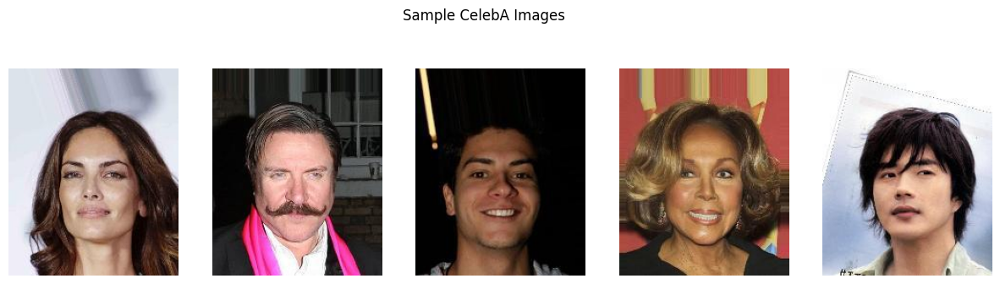

In [ ]:
# Quick peek at a few sample images
sample_files = os.listdir(IMG_DIR)[:5]
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for ax, fname in zip(axes, sample_files):
    img = plt.imread(os.path.join(IMG_DIR, fname))
    ax.imshow(img)
    ax.axis('off')
plt.suptitle("Sample CelebA Images")
plt.show()


##  Step 1: Preprocess & Load the Data

We apply the standard DCGAN preprocessing:
- **Resize** to 64×64 (a good speed/quality tradeoff for training in Colab)
- **CenterCrop** to keep the face centered
- **ToTensor()** → converts image to `[0,1]` range tensor
- **Normalize(mean=0.5, std=0.5)** for each channel → maps pixel values to `[-1, 1]`, matching the `Tanh` output of our Generator

>  For faster experimentation, we optionally use only a **subset** of the 200K images (`MAX_IMAGES`). Set it to `None` to use the full dataset (takes longer per epoch).


In [ ]:
IMAGE_SIZE = 64      # DCGAN standard size
BATCH_SIZE = 128
MAX_IMAGES = 40000   # set to None to use all ~200,000 images (slower per epoch)
NUM_WORKERS = 2

transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

class CelebADataset(Dataset):
    """Custom Dataset that reads CelebA images directly from a folder."""
    def __init__(self, root_dir, transform=None, max_images=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_files = sorted(os.listdir(root_dir))
        if max_images is not None:
            self.image_files = self.image_files[:max_images]

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        from PIL import Image
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image

dataset = CelebADataset(root_dir=IMG_DIR, transform=transform, max_images=MAX_IMAGES)
print(f"Total training images: {len(dataset)}")

Total training images: 40000


##  Step 2: Create the DataLoader

The `DataLoader` batches, shuffles, and parallelizes data loading during training.


In [ ]:
dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
)

print(f"Number of batches per epoch: {len(dataloader)}")


Number of batches per epoch: 312


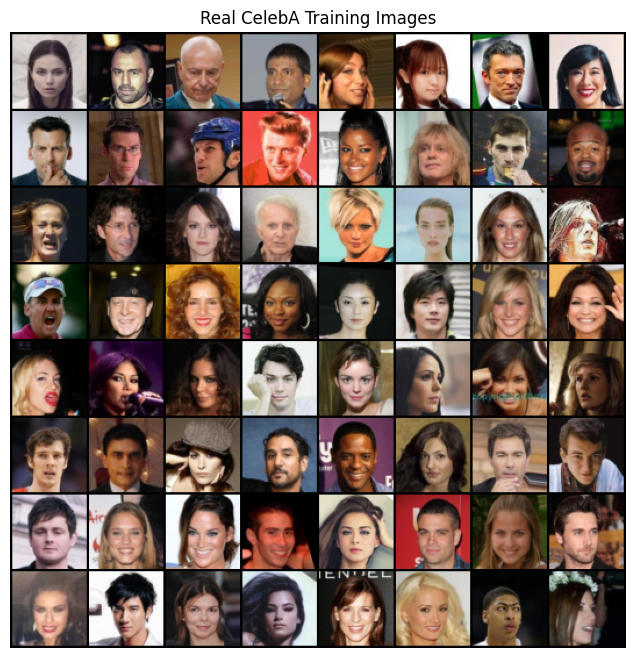

In [ ]:
# Visualize a batch of REAL training images
real_batch = next(iter(dataloader))

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Real CelebA Training Images")
grid = vutils.make_grid(real_batch[:64], padding=2, normalize=True)
plt.imshow(np.transpose(grid.cpu(), (1, 2, 0)))
plt.show()


##  Step 3: Define the Model — Generator & Discriminator

### Generator
Takes a random noise vector `z` (shape `nz x 1 x 1`) and upsamples it through a series of
`ConvTranspose2d` layers into a `3 x 64 x 64` RGB image. Uses `BatchNorm2d` + `ReLU`, with a final
`Tanh` activation (to output values in `[-1, 1]`, matching our normalized data).

### Discriminator
A standard CNN classifier: takes a `3 x 64 x 64` image and downsamples it through `Conv2d` layers
with `LeakyReLU` + `BatchNorm2d`, ending in a single `Sigmoid` output — the probability the image is real.

### Hyperparameters (DCGAN paper defaults)
- `nz = 100` → size of the latent (noise) vector
- `ngf = 64` → base number of Generator feature maps
- `ndf = 64` → base number of Discriminator feature maps
- Weight init: Normal(mean=0, std=0.02) — as recommended in the DCGAN paper


In [ ]:
# Hyperparameters
nz = 100      # size of latent noise vector
ngf = 64      # generator feature map depth
ndf = 64      # discriminator feature map depth
nc = 3        # number of channels (RGB)

def weights_init(m):
    """Custom weight initialization, as recommended in the DCGAN paper."""
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


In [ ]:
class Generator(nn.Module):
    def __init__(self, nz=100, ngf=64, nc=3):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            # input: Z, shape (nz, 1, 1) -> (ngf*8, 4, 4)
            nn.ConvTranspose2d(nz, ngf * 8, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),

            # (ngf*8, 4, 4) -> (ngf*4, 8, 8)
            nn.ConvTranspose2d(ngf * 8, ngf * 4, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),

            # (ngf*4, 8, 8) -> (ngf*2, 16, 16)
            nn.ConvTranspose2d(ngf * 4, ngf * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),

            # (ngf*2, 16, 16) -> (ngf, 32, 32)
            nn.ConvTranspose2d(ngf * 2, ngf, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),

            # (ngf, 32, 32) -> (nc, 64, 64)
            nn.ConvTranspose2d(ngf, nc, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
            # output: (nc, 64, 64), values in [-1, 1]
        )

    def forward(self, z):
        return self.main(z)


class Discriminator(nn.Module):
    def __init__(self, ndf=64, nc=3):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            # input: (nc, 64, 64) -> (ndf, 32, 32)
            nn.Conv2d(nc, ndf, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            # (ndf, 32, 32) -> (ndf*2, 16, 16)
            nn.Conv2d(ndf, ndf * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),

            # (ndf*2, 16, 16) -> (ndf*4, 8, 8)
            nn.Conv2d(ndf * 2, ndf * 4, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),

            # (ndf*4, 8, 8) -> (ndf*8, 4, 4)
            nn.Conv2d(ndf * 4, ndf * 8, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),

            # (ndf*8, 4, 4) -> (1, 1, 1)
            nn.Conv2d(ndf * 8, 1, kernel_size=4, stride=1, padding=0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, img):
        return self.main(img).view(-1)


## Step 4: Create the Complete Network

Now we:
1. Instantiate the Generator & Discriminator and move them to GPU
2. Apply the custom weight initialization
3. Define the **loss function**: Binary Cross-Entropy (`BCELoss`), since the Discriminator does binary
   real-vs-fake classification
4. Define **two separate Adam optimizers** (one per network) — DCGAN paper recommends
   `lr=0.0002`, `betas=(0.5, 0.999)`
5. Create a **fixed noise vector** — we'll use this same noise throughout training to visually track
   how the Generator's output for the *same* inputs evolves over epochs


In [ ]:
netG = Generator(nz, ngf, nc).to(device)
netG.apply(weights_init)

netD = Discriminator(ndf, nc).to(device)
netD.apply(weights_init)

print(netG)
print(netD)


Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)


In [ ]:
criterion = nn.BCELoss()

# Fixed noise to track Generator's progress on the SAME inputs across epochs
fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# Convention for real/fake labels (with slight label smoothing for stability)
real_label = 0.9   # instead of 1.0 -> "label smoothing" helps stabilize D
fake_label = 0.0

lr = 0.0002
beta1 = 0.5

optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))


##  Step 5: Train the GAN

### Training loop logic (per batch):

**(A) Update Discriminator** — maximize `log(D(x)) + log(1 - D(G(z)))`
1. Train on an all-real batch → compute loss, backprop
2. Train on an all-fake batch (from `G`) → compute loss, backprop
3. Sum both losses, step the optimizer

**(B) Update Generator** — maximize `log(D(G(z)))` (instead of minimizing `log(1-D(G(z)))`, for stronger gradients early in training)
1. Pass the fake batch through the (just-updated) `D` again
2. Compute loss **as if the fake images were labeled real** (this is what "fools the discriminator" means)
3. Backprop and step `G`'s optimizer

We save:
- Loss curves for `G` and `D`
- A grid of generated images every epoch (from `fixed_noise`) to visually see progress
- Model checkpoints periodically, and the **final trained Generator** (`generator.pth`) for later deployment

>  **Tip for classroom use:** Start with `num_epochs = 5` and `MAX_IMAGES = 20000-40000` to get visible
> results within a typical Colab session (~30-45 min on a T4 GPU). Increase both for higher quality results.


Starting Training...
[1/15][0/312]  Loss_D: 1.8975  Loss_G: 5.5679  D(x): 0.6234  D(G(z)): 0.6515 / 0.0037
[1/15][100/312]  Loss_D: 1.1093  Loss_G: 9.7434  D(x): 0.9589  D(G(z)): 0.3072 / 0.0005
[1/15][200/312]  Loss_D: 0.5593  Loss_G: 3.6788  D(x): 0.9218  D(G(z)): 0.1381 / 0.0254
[1/15][300/312]  Loss_D: 0.7662  Loss_G: 4.1489  D(x): 0.8652  D(G(z)): 0.2431 / 0.0165


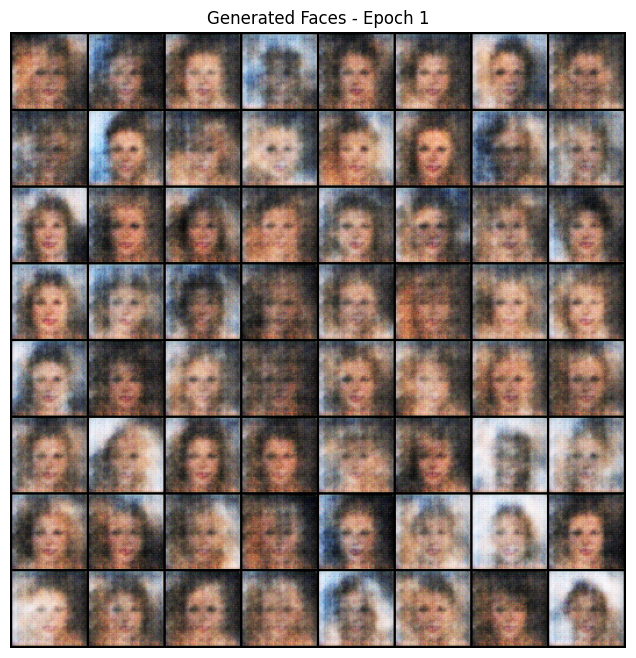

[2/15][0/312]  Loss_D: 0.7307  Loss_G: 3.9686  D(x): 0.9543  D(G(z)): 0.2318 / 0.0193
[2/15][100/312]  Loss_D: 0.7407  Loss_G: 2.4521  D(x): 0.6144  D(G(z)): 0.0618 / 0.0990
[2/15][200/312]  Loss_D: 0.6074  Loss_G: 2.5711  D(x): 0.7006  D(G(z)): 0.0598 / 0.0780
[2/15][300/312]  Loss_D: 0.5123  Loss_G: 3.6730  D(x): 0.7914  D(G(z)): 0.0456 / 0.0278


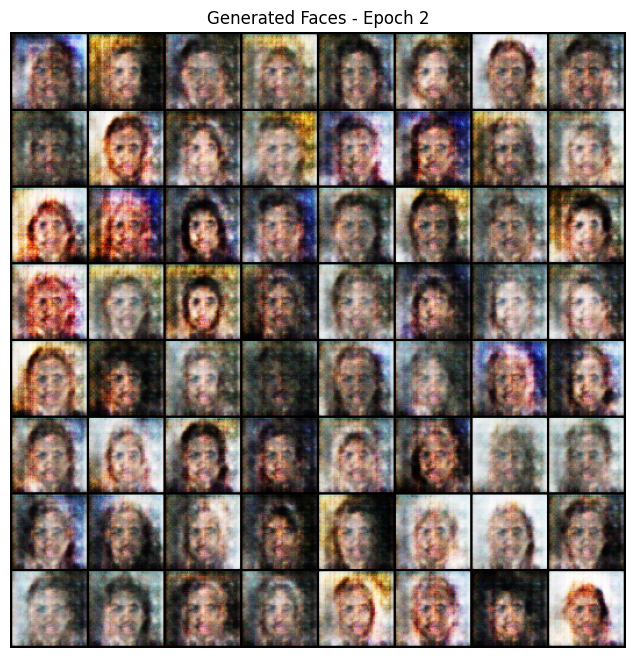

[3/15][0/312]  Loss_D: 0.9374  Loss_G: 4.3772  D(x): 0.4868  D(G(z)): 0.0044 / 0.0135
[3/15][100/312]  Loss_D: 0.9552  Loss_G: 7.5484  D(x): 0.9698  D(G(z)): 0.3447 / 0.0005
[3/15][200/312]  Loss_D: 0.5951  Loss_G: 4.5212  D(x): 0.7943  D(G(z)): 0.1424 / 0.0100
[3/15][300/312]  Loss_D: 0.6067  Loss_G: 4.6202  D(x): 0.8825  D(G(z)): 0.1629 / 0.0102


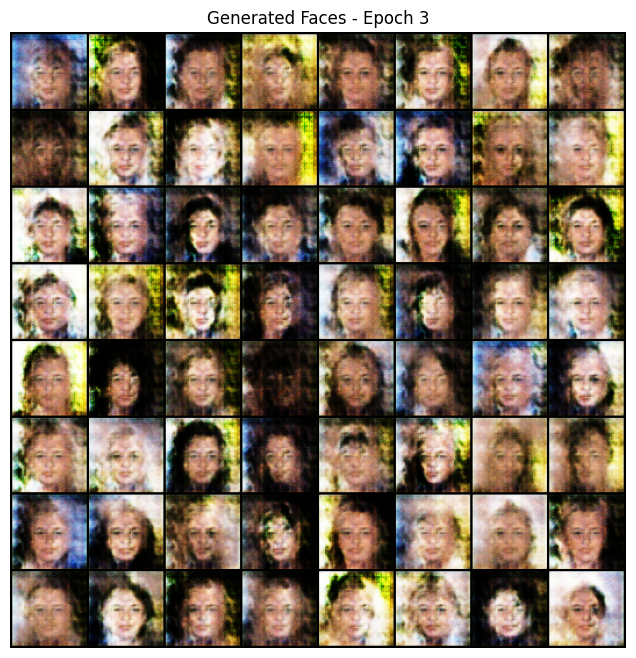

[4/15][0/312]  Loss_D: 1.2046  Loss_G: 3.1316  D(x): 0.4179  D(G(z)): 0.0170 / 0.0679
[4/15][100/312]  Loss_D: 0.6417  Loss_G: 4.1375  D(x): 0.8708  D(G(z)): 0.2021 / 0.0228
[4/15][200/312]  Loss_D: 0.9170  Loss_G: 5.1708  D(x): 0.9087  D(G(z)): 0.3646 / 0.0056
[4/15][300/312]  Loss_D: 0.8908  Loss_G: 5.2045  D(x): 0.9076  D(G(z)): 0.3560 / 0.0051


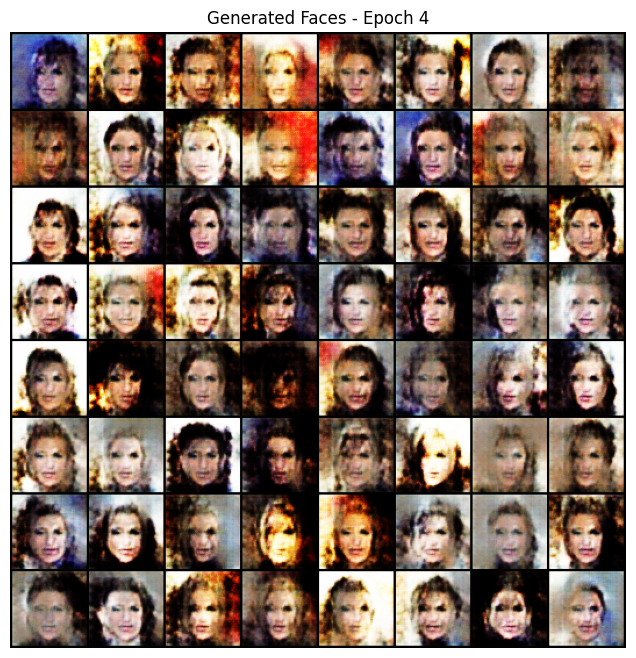

[5/15][0/312]  Loss_D: 0.8834  Loss_G: 5.2744  D(x): 0.8942  D(G(z)): 0.3438 / 0.0070
[5/15][100/312]  Loss_D: 1.1445  Loss_G: 1.8635  D(x): 0.3757  D(G(z)): 0.0130 / 0.1677
[5/15][200/312]  Loss_D: 0.8747  Loss_G: 1.9462  D(x): 0.5541  D(G(z)): 0.0881 / 0.1732
[5/15][300/312]  Loss_D: 2.5690  Loss_G: 2.2184  D(x): 0.1080  D(G(z)): 0.0025 / 0.1682


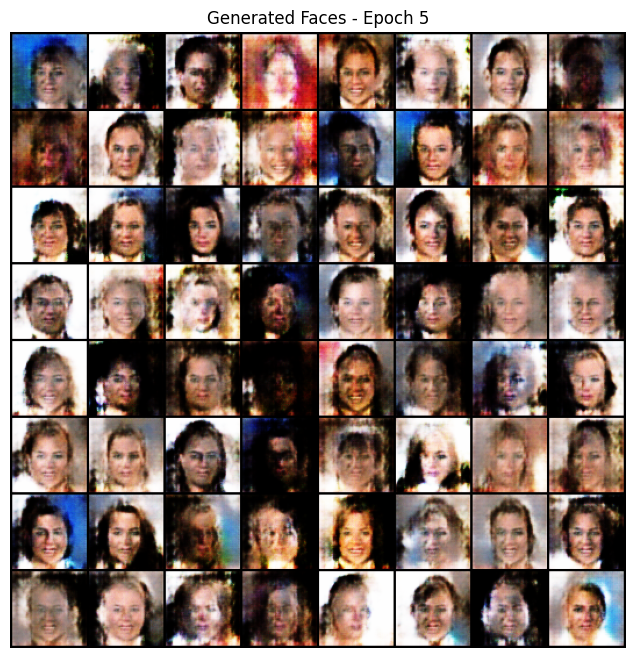

[6/15][0/312]  Loss_D: 0.6350  Loss_G: 3.4240  D(x): 0.7785  D(G(z)): 0.1697 / 0.0316
[6/15][100/312]  Loss_D: 0.6105  Loss_G: 2.7330  D(x): 0.7066  D(G(z)): 0.1012 / 0.0628
[6/15][200/312]  Loss_D: 0.7489  Loss_G: 2.3185  D(x): 0.5745  D(G(z)): 0.0130 / 0.1086
[6/15][300/312]  Loss_D: 0.7166  Loss_G: 4.5795  D(x): 0.8172  D(G(z)): 0.2388 / 0.0100


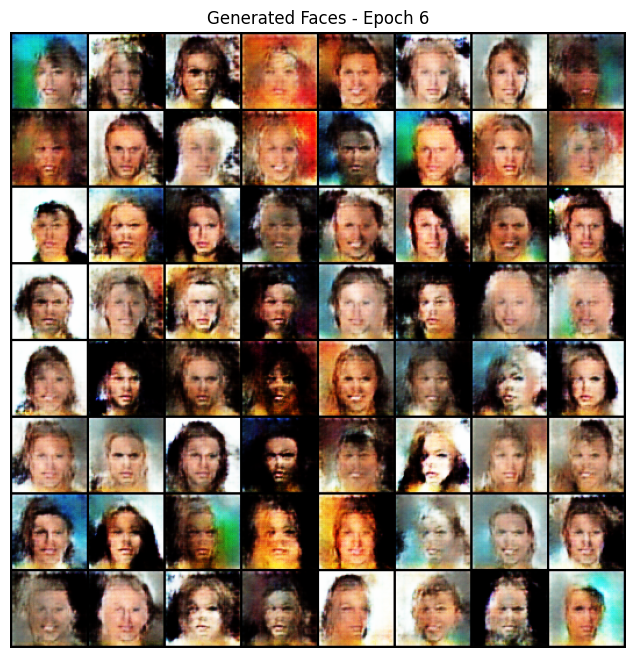

[7/15][0/312]  Loss_D: 0.5764  Loss_G: 3.0947  D(x): 0.6844  D(G(z)): 0.0541 / 0.0462
[7/15][100/312]  Loss_D: 0.8404  Loss_G: 2.8028  D(x): 0.7513  D(G(z)): 0.2805 / 0.0681
[7/15][200/312]  Loss_D: 0.7679  Loss_G: 2.1293  D(x): 0.6574  D(G(z)): 0.1620 / 0.1159
[7/15][300/312]  Loss_D: 0.6566  Loss_G: 2.5889  D(x): 0.7242  D(G(z)): 0.1602 / 0.0742


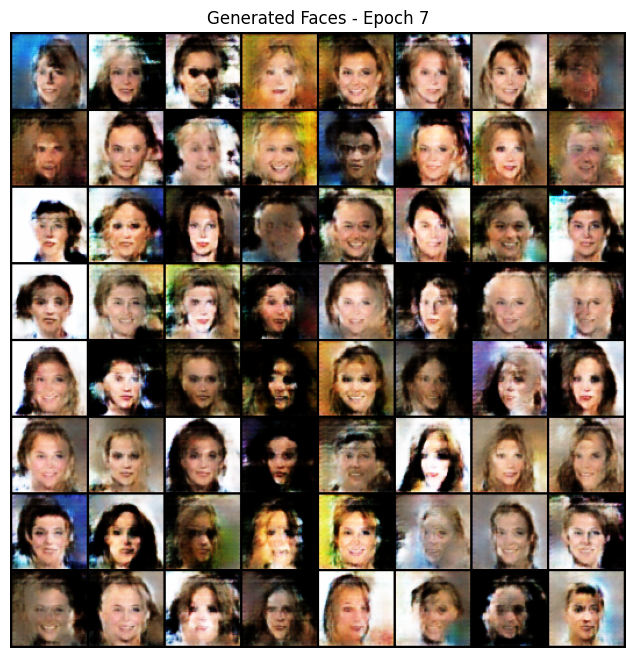

[8/15][0/312]  Loss_D: 0.6056  Loss_G: 2.7666  D(x): 0.7532  D(G(z)): 0.1229 / 0.0620
[8/15][100/312]  Loss_D: 0.6998  Loss_G: 3.2311  D(x): 0.8101  D(G(z)): 0.2349 / 0.0382
[8/15][200/312]  Loss_D: 1.3359  Loss_G: 0.6148  D(x): 0.3346  D(G(z)): 0.0372 / 0.6182
[8/15][300/312]  Loss_D: 1.1303  Loss_G: 0.7877  D(x): 0.3689  D(G(z)): 0.0265 / 0.5006


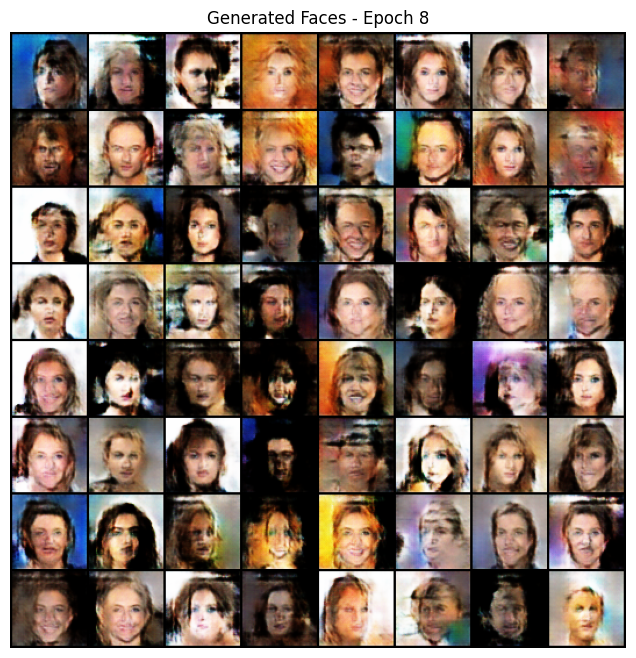

[9/15][0/312]  Loss_D: 0.6857  Loss_G: 2.9465  D(x): 0.7651  D(G(z)): 0.2042 / 0.0491
[9/15][100/312]  Loss_D: 0.6010  Loss_G: 2.8761  D(x): 0.7784  D(G(z)): 0.1522 / 0.0535
[9/15][200/312]  Loss_D: 0.7045  Loss_G: 2.9737  D(x): 0.8339  D(G(z)): 0.2617 / 0.0481
[9/15][300/312]  Loss_D: 0.7563  Loss_G: 2.4783  D(x): 0.6652  D(G(z)): 0.1710 / 0.0830


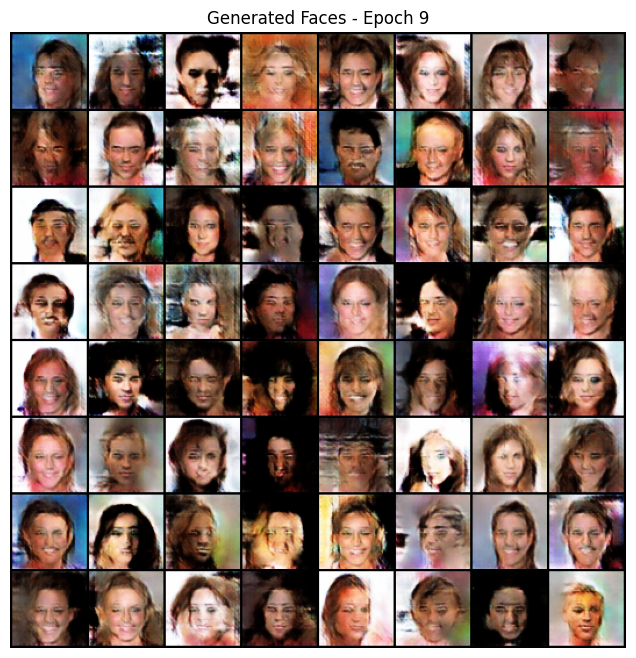

[10/15][0/312]  Loss_D: 0.8668  Loss_G: 3.5495  D(x): 0.8712  D(G(z)): 0.3602 / 0.0295
[10/15][100/312]  Loss_D: 1.0068  Loss_G: 3.5358  D(x): 0.7590  D(G(z)): 0.4011 / 0.0277
[10/15][200/312]  Loss_D: 2.8475  Loss_G: 0.5443  D(x): 0.0699  D(G(z)): 0.0088 / 0.6781
[10/15][300/312]  Loss_D: 0.8879  Loss_G: 3.0709  D(x): 0.8645  D(G(z)): 0.3670 / 0.0435


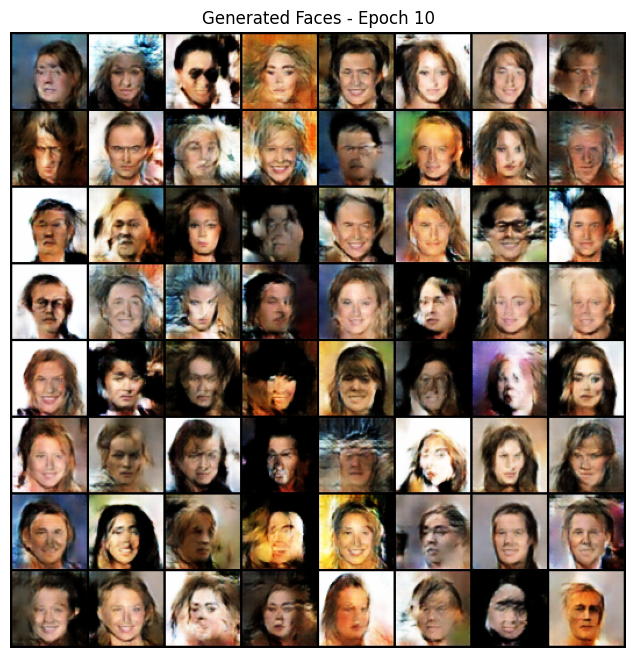

[11/15][0/312]  Loss_D: 0.7050  Loss_G: 3.2093  D(x): 0.8497  D(G(z)): 0.2617 / 0.0355
[11/15][100/312]  Loss_D: 0.8187  Loss_G: 1.9046  D(x): 0.5706  D(G(z)): 0.1313 / 0.1496
[11/15][200/312]  Loss_D: 0.7569  Loss_G: 2.1182  D(x): 0.6224  D(G(z)): 0.1418 / 0.1210
[11/15][300/312]  Loss_D: 1.4791  Loss_G: 0.6476  D(x): 0.2528  D(G(z)): 0.0269 / 0.5756


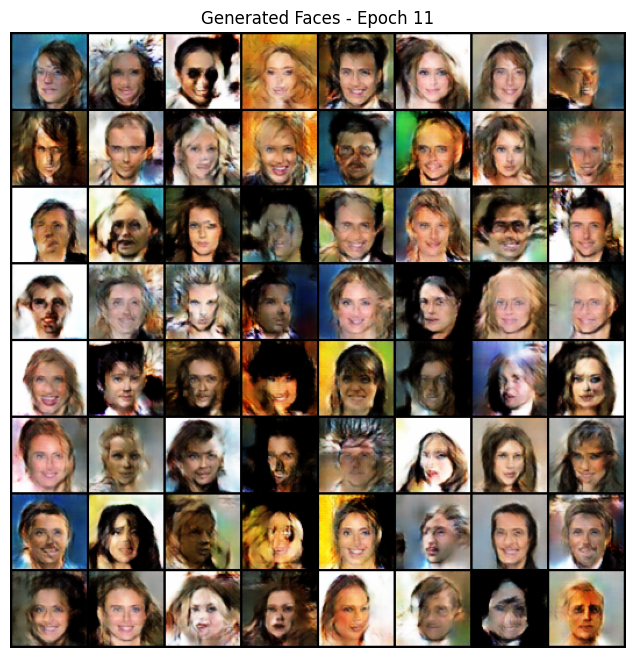

[12/15][0/312]  Loss_D: 0.7396  Loss_G: 3.0221  D(x): 0.8490  D(G(z)): 0.2873 / 0.0462
[12/15][100/312]  Loss_D: 1.0685  Loss_G: 4.3928  D(x): 0.9046  D(G(z)): 0.4759 / 0.0105
[12/15][200/312]  Loss_D: 0.8470  Loss_G: 3.0157  D(x): 0.7005  D(G(z)): 0.2724 / 0.0506
[12/15][300/312]  Loss_D: 0.7347  Loss_G: 2.9410  D(x): 0.8200  D(G(z)): 0.2783 / 0.0480


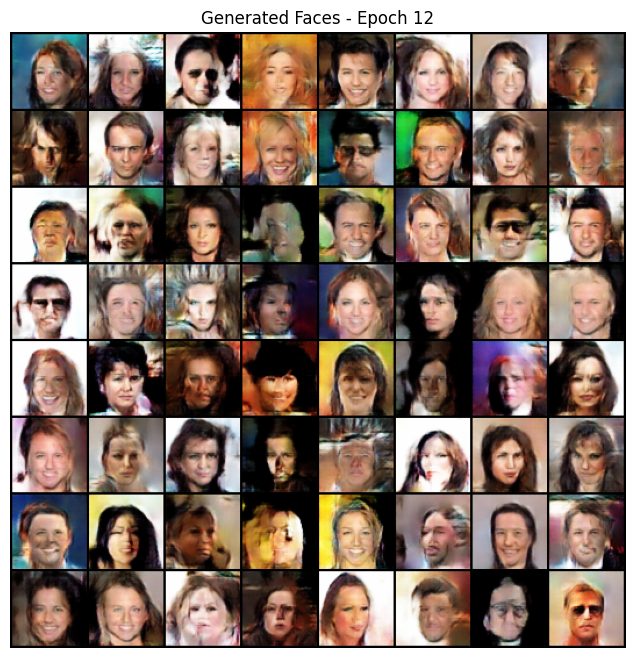

[13/15][0/312]  Loss_D: 0.9534  Loss_G: 1.6320  D(x): 0.4647  D(G(z)): 0.0929 / 0.2046
[13/15][100/312]  Loss_D: 1.0053  Loss_G: 0.8652  D(x): 0.4082  D(G(z)): 0.0468 / 0.4577
[13/15][200/312]  Loss_D: 0.8010  Loss_G: 1.8348  D(x): 0.5649  D(G(z)): 0.1200 / 0.1620
[13/15][300/312]  Loss_D: 0.9077  Loss_G: 1.6620  D(x): 0.5984  D(G(z)): 0.2412 / 0.1924


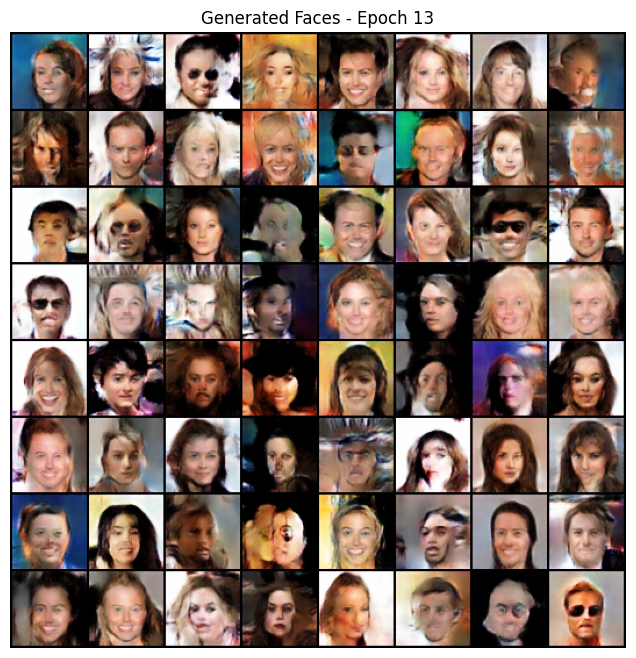

[14/15][0/312]  Loss_D: 0.6930  Loss_G: 2.1802  D(x): 0.7427  D(G(z)): 0.2019 / 0.1040
[14/15][100/312]  Loss_D: 0.6890  Loss_G: 2.9252  D(x): 0.7678  D(G(z)): 0.2287 / 0.0490
[14/15][200/312]  Loss_D: 1.2690  Loss_G: 4.2824  D(x): 0.8627  D(G(z)): 0.5509 / 0.0127
[14/15][300/312]  Loss_D: 0.9549  Loss_G: 3.7593  D(x): 0.8165  D(G(z)): 0.4040 / 0.0204


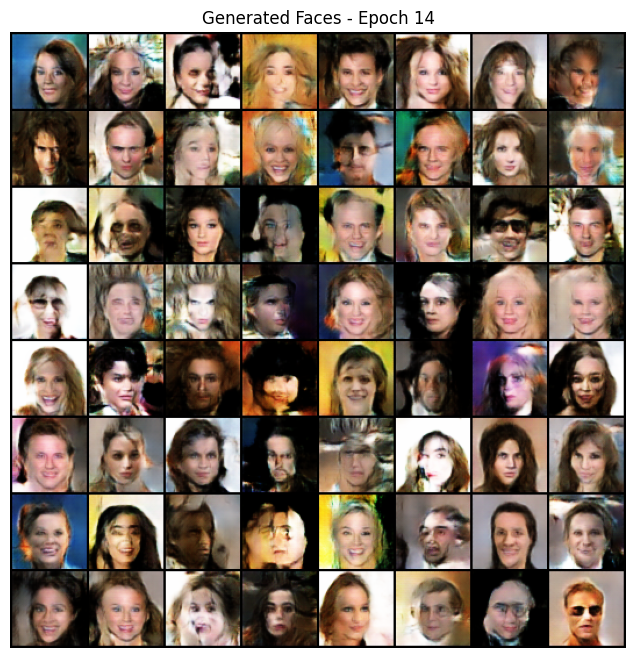

[15/15][0/312]  Loss_D: 0.6416  Loss_G: 2.3729  D(x): 0.7639  D(G(z)): 0.1949 / 0.0881
[15/15][100/312]  Loss_D: 0.9197  Loss_G: 2.4142  D(x): 0.7925  D(G(z)): 0.3808 / 0.0851
[15/15][200/312]  Loss_D: 0.7484  Loss_G: 2.3952  D(x): 0.7488  D(G(z)): 0.2434 / 0.0926
[15/15][300/312]  Loss_D: 0.8563  Loss_G: 2.1803  D(x): 0.7022  D(G(z)): 0.2954 / 0.1092


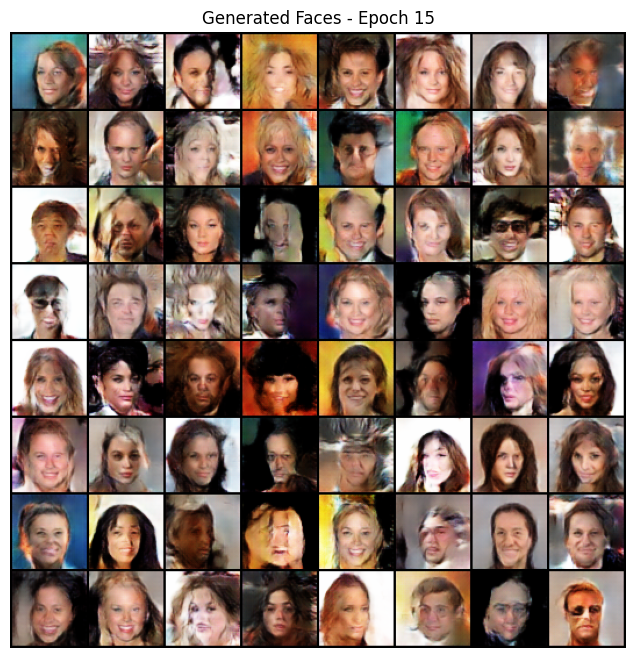


Training complete in 13.7 minutes.


In [ ]:
num_epochs = 15
CHECKPOINT_DIR = "/content/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

G_losses = []
D_losses = []
img_list = []

print("Starting Training...")
start_time = time.time()

for epoch in range(num_epochs):
    for i, real_images in enumerate(dataloader):

        real_images = real_images.to(device)
        b_size = real_images.size(0)

        # ---------------------------
        # (A) Update Discriminator
        # ---------------------------
        netD.zero_grad()

        # -- train with real batch --
        label = torch.full((b_size,), real_label, dtype=torch.float, device=device)
        output = netD(real_images)
        errD_real = criterion(output, label)
        errD_real.backward()
        D_x = output.mean().item()

        # -- train with fake batch --
        noise = torch.randn(b_size, nz, 1, 1, device=device)
        fake_images = netG(noise)
        label.fill_(fake_label)
        output = netD(fake_images.detach())
        errD_fake = criterion(output, label)
        errD_fake.backward()
        D_G_z1 = output.mean().item()

        errD = errD_real + errD_fake
        optimizerD.step()

        # ---------------------------
        # (B) Update Generator
        # ---------------------------
        netG.zero_grad()
        label.fill_(real_label)          # fake labels are "real" for generator cost
        output = netD(fake_images)
        errG = criterion(output, label)
        errG.backward()
        D_G_z2 = output.mean().item()
        optimizerG.step()

        # Logging
        if i % 100 == 0:
            print(f"[{epoch+1}/{num_epochs}][{i}/{len(dataloader)}]  "
                  f"Loss_D: {errD.item():.4f}  Loss_G: {errG.item():.4f}  "
                  f"D(x): {D_x:.4f}  D(G(z)): {D_G_z1:.4f} / {D_G_z2:.4f}")

        G_losses.append(errG.item())
        D_losses.append(errD.item())

    # ---- End of epoch: save a snapshot grid from fixed noise ----
    with torch.no_grad():
        fake = netG(fixed_noise).detach().cpu()
    grid = vutils.make_grid(fake, padding=2, normalize=True)
    img_list.append(grid)

    plt.figure(figsize=(8, 8))
    plt.axis("off")
    plt.title(f"Generated Faces - Epoch {epoch+1}")
    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.savefig(f"{CHECKPOINT_DIR}/epoch_{epoch+1}.png")
    plt.show()

    # Save periodic checkpoints
    torch.save(netG.state_dict(), f"{CHECKPOINT_DIR}/generator_epoch_{epoch+1}.pth")
    torch.save(netD.state_dict(), f"{CHECKPOINT_DIR}/discriminator_epoch_{epoch+1}.pth")

elapsed = time.time() - start_time
print(f"\nTraining complete in {elapsed/60:.1f} minutes.")


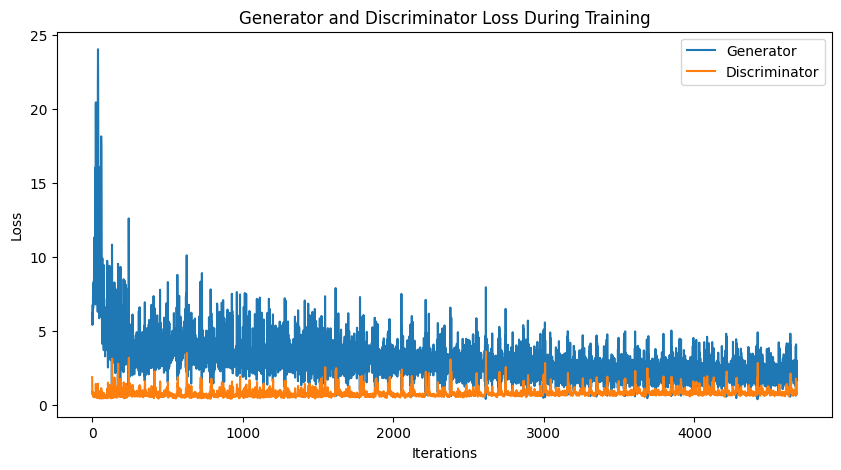

In [ ]:
# ---- Plot training losses ----
plt.figure(figsize=(10, 5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses, label="Generator")
plt.plot(D_losses, label="Discriminator")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()


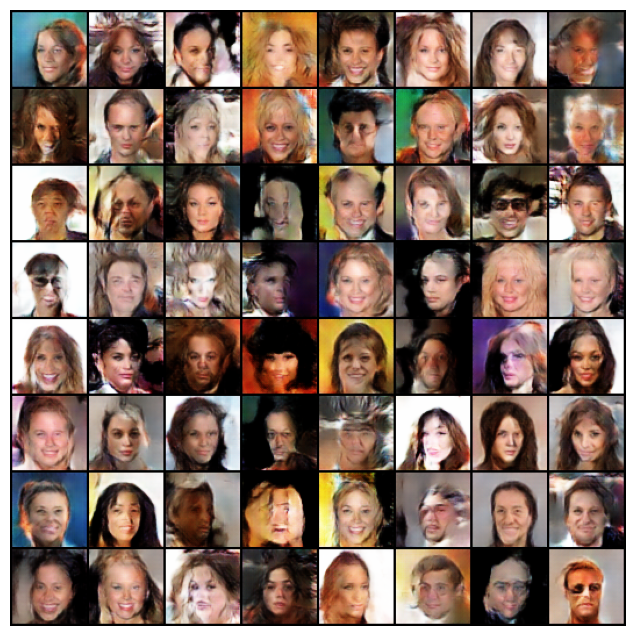

In [ ]:
# ---- Animate Generator's progress across epochs ----
fig = plt.figure(figsize=(8, 8))
plt.axis("off")
ims = [[plt.imshow(np.transpose(img, (1, 2, 0)), animated=True)] for img in img_list]
ani = animation.ArtistAnimation(fig, ims, interval=1000, repeat_delay=1000, blit=True)
HTML(ani.to_jshtml())


In [ ]:
# ---- Save the FINAL trained Generator model (for the Flask app) ----
FINAL_MODEL_PATH = "/content/generator.pth"
torch.save(netG.state_dict(), FINAL_MODEL_PATH)
print(f"Final generator model saved to: {FINAL_MODEL_PATH}")

# Download it to your local machine (you'll place this file in your Flask project folder)
from google.colab import files
files.download(FINAL_MODEL_PATH)


Final generator model saved to: /content/generator.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##  Step 6: Generate New Faces

Now that the Generator is trained, we can feed it **brand-new random noise vectors** to produce
faces it has never generated before — this is exactly what our Flask app's "Generate Face" button
will do.


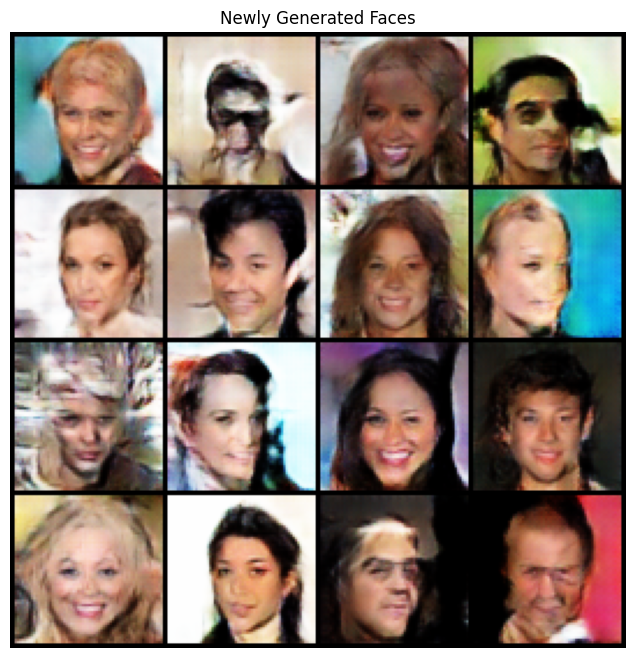

In [ ]:
def generate_faces(generator, num_images=16, nz=100, device=device):
    """Generate a batch of new face images using the trained Generator."""
    generator.eval()
    with torch.no_grad():
        noise = torch.randn(num_images, nz, 1, 1, device=device)
        fake_images = generator(noise).detach().cpu()
    generator.train()
    return fake_images

# Generate and display a grid of new faces
new_faces = generate_faces(netG, num_images=16)

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Newly Generated Faces")
grid = vutils.make_grid(new_faces, padding=2, normalize=True, nrow=4)
plt.imshow(np.transpose(grid, (1, 2, 0)))
plt.show()


Saved a single generated face to /content/single_generated_face.png


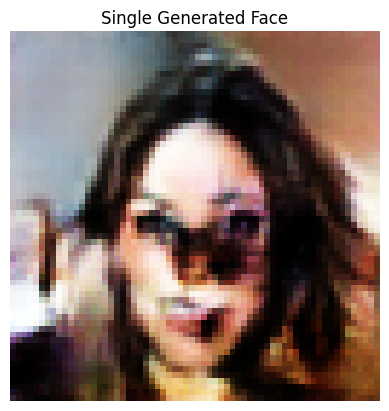

In [ ]:
# ---- Save ONE generated face as a standalone PNG (like the Flask app will do) ----
from torchvision.utils import save_image

single_noise = torch.randn(1, nz, 1, 1, device=device)
with torch.no_grad():
    single_face = netG(single_noise).detach().cpu()

save_image(single_face, "/content/single_generated_face.png", normalize=True)
print("Saved a single generated face to /content/single_generated_face.png")

img = plt.imread("/content/single_generated_face.png")
plt.imshow(img)
plt.axis('off')
plt.title("Single Generated Face")
plt.show()


##  Summary & Next Steps

You have now:
- Loaded and preprocessed the CelebA dataset
- Built a DCGAN (Generator + Discriminator) from scratch in PyTorch
- Trained it with the adversarial min-max objective
- Generated new, synthetic celebrity-like faces
- Exported `generator.pth` — ready to be plugged into a web app

###  Deploying this model
Download `generator.pth` from this notebook (already triggered above), then use it with the companion
**Flask web application** (provided separately) that has a simple **"Generate Face" button UI**.

### Ideas for Extending This Project (great for a B.Tech mini-project report)
- Train for more epochs / on the full 200K images for sharper results
- Try **Wasserstein GAN (WGAN-GP)** for more stable training
- Add **conditional generation** (e.g., generate faces with/without glasses, smiling, etc.) using CelebA's attribute labels → **Conditional GAN (cGAN)**
- Try **StyleGAN2** for much higher resolution, higher quality faces
- Add an **interpolation slider** in the UI to morph between two generated faces (interpolate in latent space)
